# Русский биомедицинский поиск: новая фаза

Реальный полныйtest nDCG@10 **0.3756**, **+7.83%** к published .3483. Быстрый режим проверяет опубликованные ranks/grades и все dev trials; модели повторно не запускаются.

In [1]:
from pathlib import Path
import os,json,subprocess,sys
ROOT=Path.cwd()
if not (ROOT/"project.json").exists():
    ROOT=ROOT/"russian-biomedical-retrieval"
    if not ROOT.exists():
        subprocess.run(["git","clone","https://github.com/NikiBagramov/russian-biomedical-retrieval",str(ROOT)],check=True)
os.chdir(ROOT)
assert json.loads((ROOT/"project.json").read_text(encoding="utf-8"))["slug"]=="russian-biomedical-retrieval"
print(ROOT.name)

russian-biomedical-retrieval


In [2]:
INSTALL=False
if INSTALL:
    subprocess.run([sys.executable,"-m","pip","install","-r","requirements.txt"],check=True)

In [3]:
subprocess.run([sys.executable,"scripts/run_pipeline.py","--verify"],check=True)

CompletedProcess(args=['C:\\Users\\nbagr\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', 'scripts/run_pipeline.py', '--verify'], returncode=0)

In [4]:
import pandas as pd
display(pd.read_csv("experiments/phase2/artifacts/results.csv"))

,method,P_10,recall_10,recall_100,ndcg_cut_10,map_cut_10,mrr_10
0,phase2_selected,0.269659,0.183899,0.308671,0.375585,0.145625,0.596402
1,phase2_retrieval,0.254489,0.172248,0.308671,0.353268,0.135519,0.567237
2,phase1_selected,0.251393,0.174263,0.284613,0.352470,0.136641,0.566126
3,bm25,0.215789,0.154147,0.242953,0.303818,0.117720,0.491296
4,bm25_bge512,0.229412,0.157869,0.242953,0.328244,0.126413,0.541126
5,phase1_qwen06,0.250155,0.168668,0.284613,0.348200,0.133215,0.555605


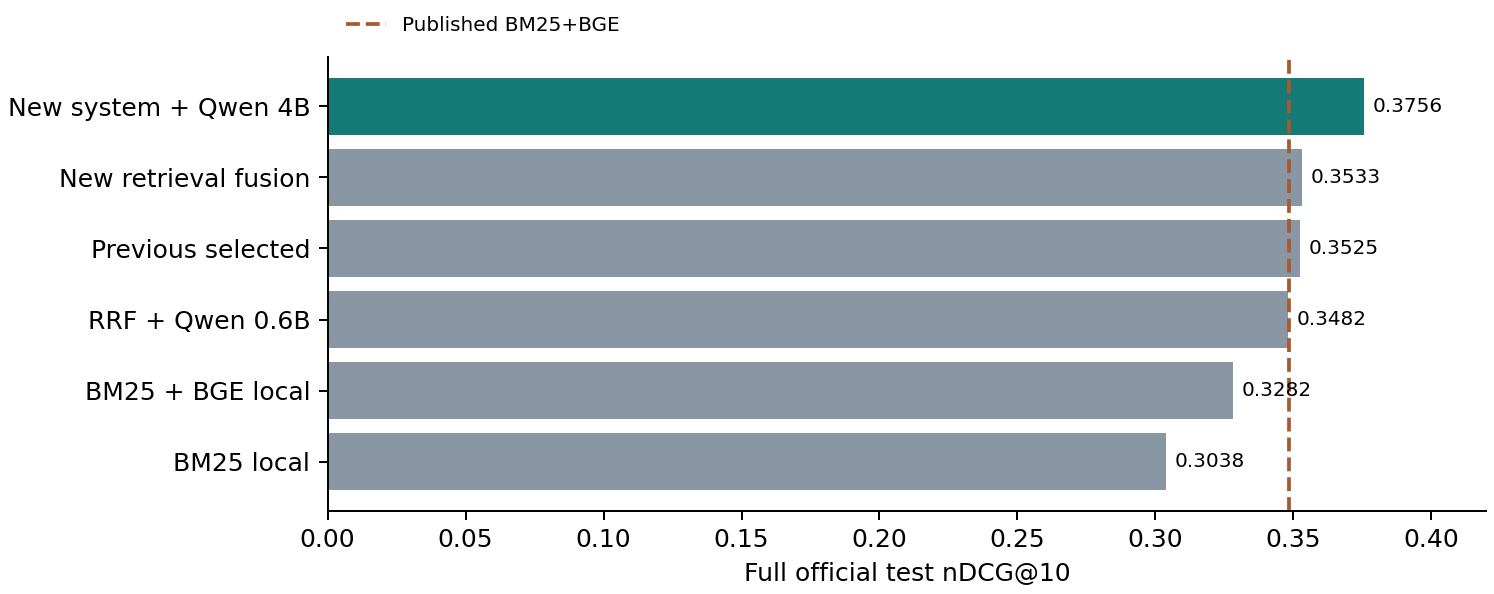

In [5]:
from IPython.display import display,Image
display(Image(filename="artifacts/figures/phase2_main.png"))

## Полное новое воспроизведение

Требует BF16 GPU, скачивания pinned weights и часов вычислений. Новый runs/phase2_reproduce_* сохраняет исходные artifacts. Быстрый notebook не подменяет полный inference.

In [6]:
RUN_FULL=False
if RUN_FULL:
    subprocess.run([sys.executable,"scripts/run_pipeline.py","--reproduce","--download","--report"],check=True)

## Ограничения

Test уже оценивался в фазе1; фазе2 предшествовал новый dev-only selection lock. CPU BM25, контекст, модельный размер и dev-adaptation отличаются от статьи. Published aggregate сравнивается численно; paired bootstrap относится к локальным запускам. Глобальное SotA и оценка преподавателя не гарантируются.